# 06 – Predictive modelling
Notebooks 03–04 showed that hot days are busier. This notebook asks a practical follow-up question:

**Can the next day's number of EMS missions be predicted, and does temperature make that prediction better?**

This is a **retrospective forecast experiment**, not a tested operational forecast: the model is given the *measured* maximum temperature of the day it predicts, as a stand-in for a weather forecast. Section 6 checks how much the result depends on that.

- **Target:** daily EMS missions (`ems_missions`).
- **Approach:** supervised regression. A naive baseline is compared with linear regression, a random forest and gradient boosting.
- **Validation:** models are compared on 2018–2025 with leave-one-summer-out validation (each summer is predicted by a model that never saw it). The summer of 2026 is held back as a final test and used only once.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raw_folder = Path("../data/raw")
clean_folder = Path("../data/clean")
figures_folder = Path("../figures")
tableau_folder = Path("../tableau")

daily = pd.read_csv(clean_folder / "daily_summer.csv", parse_dates=["date"])
daily = daily.sort_values("date").reset_index(drop=True)
print(daily.shape)

(891, 13)


## 1. Features
Every feature must be known **before** the day starts, otherwise the model would be cheating.

| Feature | Meaning | Known in advance? |
|---|---|---|
| `recent_missions` | average EMS missions over the previous 7 days | yes (past data) |
| `tmax` | maximum temperature of the day | only as a weather forecast; the measured value is used here |
| `recent_tmax` | average maximum temperature over the previous 7 days | yes (past data) |
| `weekday`, `month` | calendar | yes |

`recent_missions` replaces the yearly index from Notebooks 03–05. The index needs the average of the *whole* summer, which is unknown while the summer is still running. The last 7 days are always known.

`daily_summer.csv` only has mission counts from 1 June. To give the first days of June a full 7-day history, the counts for 25–31 May are read from the raw file.

In [2]:
raw_missions = pd.read_csv(raw_folder / "BFw_mission_data_daily.csv", parse_dates=["mission_created_date"])
raw_missions = raw_missions[["mission_created_date", "mission_count_ems"]]
raw_missions.columns = ["date", "ems_raw"]

daily = daily.merge(raw_missions, on="date", how="left", validate="one_to_one")

# Summer days keep the cleaned values (7 June 2018 and the missing 2026 days stay empty).
# Only the late-May helper days are filled from the raw file.
late_may = daily["in_summer"] == 0
daily["missions_history"] = daily["ems_missions"]
daily.loc[late_may, "missions_history"] = daily.loc[late_may, "ems_raw"]

print("Late-May days with mission data:", daily.loc[late_may, "missions_history"].notna().sum(), "of", late_may.sum())

Late-May days with mission data: 63 of 63


In [3]:
# shift(1) = only days BEFORE today are used. Grouping by year stops one summer leaking into the next.
def previous_7_day_mean(series):
    return series.shift(1).rolling(7, min_periods=4).mean()

daily["recent_missions"] = daily.groupby("year")["missions_history"].transform(previous_7_day_mean)
daily["recent_tmax"] = daily.groupby("year")["tmax"].transform(previous_7_day_mean)

model_data = daily[(daily["in_summer"] == 1) & daily["ems_missions"].notna()].copy()

print(model_data.shape)
print("Missing feature values:")
print(model_data[["recent_missions", "tmax", "recent_tmax"]].isna().sum())
model_data[["date", "ems_missions", "recent_missions", "tmax", "recent_tmax"]].head()

(822, 17)
Missing feature values:
recent_missions    0
tmax               0
recent_tmax        0
dtype: int64


,date,ems_missions,recent_missions,tmax,recent_tmax
7,2018-06-01,1357.0,1217.428571,32.2,30.071429
8,2018-06-02,1188.0,1244.000000,26.4,30.828571
9,2018-06-03,1194.0,1247.571429,24.1,30.700000
10,2018-06-04,1275.0,1254.571429,25.4,30.114286
11,2018-06-05,1171.0,1264.285714,23.5,29.157143


In [4]:
numeric_features = ["recent_missions", "tmax", "recent_tmax"]

# One-hot encoding for weekday and month. Reference categories: Friday and June.
calendar = pd.get_dummies(model_data[["weekday", "month"]].astype({"month": str}), drop_first=True)

X = pd.concat([model_data[numeric_features], calendar], axis=1)
y = model_data["ems_missions"]

# Development set (model comparison) and final test set (touched once, at the end)
dev = model_data["year"] <= 2025
test = model_data["year"] == 2026

X_dev, y_dev, years_dev = X[dev], y[dev], model_data.loc[dev, "year"]
X_test, y_test = X[test], y[test]

print("Features:", list(X.columns))
print(f"Development: {len(X_dev)} days (2018–2025) | Test: {len(X_test)} days (2026)")

Features: ['recent_missions', 'tmax', 'recent_tmax', 'weekday_Monday', 'weekday_Saturday', 'weekday_Sunday', 'weekday_Thursday', 'weekday_Tuesday', 'weekday_Wednesday', 'month_7', 'month_8']
Development: 735 days (2018–2025) | Test: 87 days (2026)


## 2. Baseline
A model is only useful if it beats a simple rule. The naive forecast is: **"tomorrow will look like the average of the last 7 days"** (`recent_missions`).

Metrics, all in missions per day:
- **MAE**: average size of the error. The main metric, easy to explain.
- **RMSE**: like MAE, but punishes large errors more.
- **R²**: share of the day-to-day variation that is explained.

In [5]:
def scores(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

naive_dev = model_data.loc[dev, "recent_missions"]
naive_test = model_data.loc[test, "recent_missions"]

print("Naive forecast, 2018–2025:")
print(pd.Series(scores(y_dev, naive_dev)).round(2))

Naive forecast, 2018–2025:
MAE     56.90
RMSE    72.66
R2       0.55
dtype: float64


## 3. Model comparison (2018–2025)
**Leave-one-summer-out cross-validation:** each summer is predicted by a model trained on the other seven. A normal random split would put neighbouring days of the same heatwave into both training and test data and make the results look better than they are.

This is not a chronological test: the model that predicts 2018 has been trained on later summers. Only the 2026 test in section 5 is strictly "past predicts future".

The tree models use fixed, moderate settings.

In [6]:
models = {
    "Linear regression": LinearRegression(),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=2, random_state=42),
}

cv = LeaveOneGroupOut()
cv_predictions = {}
cv_results = {"Naive (last 7 days)": scores(y_dev, naive_dev)}

for name, model in models.items():
    cv_predictions[name] = cross_val_predict(model, X_dev, y_dev, groups=years_dev, cv=cv)
    cv_results[name] = scores(y_dev, cv_predictions[name])

cv_table = pd.DataFrame(cv_results).T
cv_table["MAE vs naive (%)"] = (cv_table["MAE"] / cv_table.loc["Naive (last 7 days)", "MAE"] - 1) * 100
cv_table.round(2)

,MAE,RMSE,R2,MAE vs naive (%)
Naive (last 7 days),56.90,72.66,0.55,0.00
Linear regression,42.81,55.15,0.74,-24.76
Random forest,47.42,61.05,0.68,-16.65
Gradient boosting,45.31,58.24,0.71,-20.37


In [7]:
best_name = cv_table.drop(index="Naive (last 7 days)")["MAE"].idxmin()
print("Selected model (lowest cross-validated MAE):", best_name)

# Is the result stable across summers?
per_summer = pd.DataFrame({
    "naive": (y_dev - naive_dev).abs().groupby(years_dev).mean(),
    "model": (y_dev - cv_predictions[best_name]).abs().groupby(years_dev).mean(),
})
per_summer["model_better"] = per_summer["model"] < per_summer["naive"]
per_summer.round(1)

Selected model (lowest cross-validated MAE): Linear regression


,naive,model,model_better
year,,,
2018,59.2,43.4,True
2019,58.2,42.6,True
2020,53.8,41.0,True
2021,57.0,46.7,True
2022,53.4,48.3,True
2023,48.9,33.9,True
2024,61.5,42.5,True
2025,63.1,44.0,True


## 4. Does temperature improve the forecast?
The features are added step by step to a linear regression. If temperature carries real predictive information, the error must fall when it is added.

In [8]:
calendar_columns = list(calendar.columns)

steps = {
    "Recent demand + calendar": ["recent_missions"] + calendar_columns,
    "+ today's temperature": ["recent_missions", "tmax"] + calendar_columns,
    "+ recent temperature": ["recent_missions", "tmax", "recent_tmax"] + calendar_columns,
}

step_results = {"Naive (last 7 days)": scores(y_dev, naive_dev)}
for name, columns in steps.items():
    predictions = cross_val_predict(LinearRegression(), X_dev[columns], y_dev, groups=years_dev, cv=cv)
    step_results[name] = scores(y_dev, predictions)

step_table = pd.DataFrame(step_results).T
step_table.round(2)

,MAE,RMSE,R2
Naive (last 7 days),56.90,72.66,0.55
Recent demand + calendar,53.43,68.65,0.59
+ today's temperature,47.51,61.14,0.68
+ recent temperature,42.81,55.15,0.74


## 5. Final test: summer 2026
The models are trained on all of 2018–2025 and predict 2026, a summer they have never seen. 2026 is a hard test: it includes the record heatwave, with temperatures and mission counts above anything in the training data.

In [9]:
test_predictions = {}
test_results = {"Naive (last 7 days)": scores(y_test, naive_test)}

for name, model in models.items():
    model.fit(X_dev, y_dev)
    test_predictions[name] = model.predict(X_test)
    test_results[name] = scores(y_test, test_predictions[name])

test_table = pd.DataFrame(test_results).T
test_table["MAE vs naive (%)"] = (test_table["MAE"] / test_table.loc["Naive (last 7 days)", "MAE"] - 1) * 100
test_table.round(2)

,MAE,RMSE,R2,MAE vs naive (%)
Naive (last 7 days),82.02,105.04,0.28,0.00
Linear regression,54.81,73.94,0.64,-33.18
Random forest,76.83,111.16,0.19,-6.32
Gradient boosting,78.28,115.34,0.13,-4.56


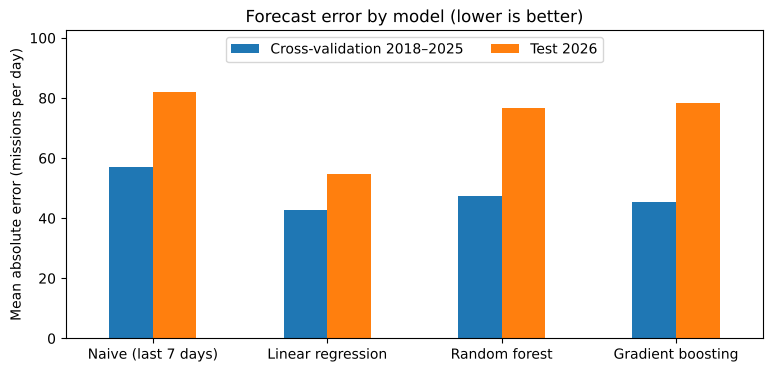

In [10]:
comparison = pd.DataFrame({"Cross-validation 2018–2025": cv_table["MAE"], "Test 2026": test_table["MAE"]})

ax = comparison.plot(kind="bar", figsize=(9, 4), rot=0)
ax.set_ylabel("Mean absolute error (missions per day)")
ax.set_title("Forecast error by model (lower is better)")
ax.set_ylim(0, comparison.max().max() * 1.25)
ax.legend(loc="upper center", ncol=2)

plt.savefig(figures_folder / "ml_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Collect the out-of-sample forecasts of the selected model in one table:
# cross-validated predictions for 2018–2025, test predictions for 2026
model_data["evaluation"] = np.where(test, "Test (2026)", "Cross-validation (2018–2025)")
model_data["naive"] = model_data["recent_missions"]
model_data.loc[dev, "predicted"] = cv_predictions[best_name]
model_data.loc[test, "predicted"] = test_predictions[best_name]

model_data["naive_error"] = model_data["naive"] - model_data["ems_missions"]
model_data["model_error"] = model_data["predicted"] - model_data["ems_missions"]
model_data["naive_abs_error"] = model_data["naive_error"].abs()
model_data["model_abs_error"] = model_data["model_error"].abs()

# Where does the model help? Normal days (0) vs. hot days (1)
model_data.groupby(["evaluation", "hot_day"]).agg(
    days=("date", "size"),
    naive_mae=("naive_abs_error", "mean"),
    model_mae=("model_abs_error", "mean"),
    model_bias=("model_error", "mean")
).round(1)

days  naive_mae  model_mae  model_bias
evaluation                   hot_day                                        
Cross-validation (2018–2025) 0         599       54.3       41.8         0.5
                             1         136       68.1       47.1        -1.8
Test (2026)                  0          68       77.4       49.6        -2.3
                             1          19       98.5       73.4       -46.0

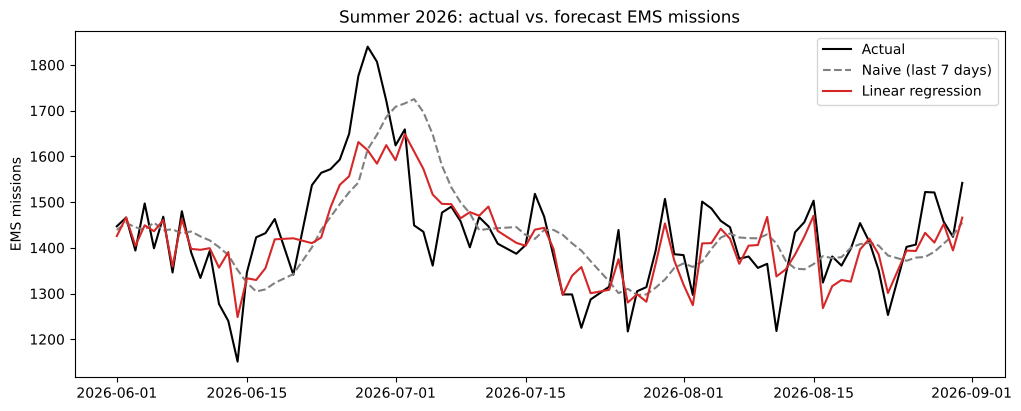

In [12]:
summer_2026 = model_data[test]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(summer_2026["date"], summer_2026["ems_missions"], color="black", linewidth=1.5, label="Actual")
ax.plot(summer_2026["date"], summer_2026["naive"], color="grey", linestyle="--", label="Naive (last 7 days)")
ax.plot(summer_2026["date"], summer_2026["predicted"], color="tab:red", label=best_name)
ax.set_ylabel("EMS missions")
ax.set_title("Summer 2026: actual vs. forecast EMS missions")
ax.legend()

plt.savefig(figures_folder / "ml_forecast_2026.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
# The record heatwave in detail
heatwave = summer_2026[summer_2026["date"].between("2026-06-24", "2026-07-04")]
heatwave[["date", "tmax", "ems_missions", "naive", "predicted", "model_error"]].round({"naive": 0, "predicted": 0, "model_error": 0})

,date,tmax,ems_missions,naive,predicted,model_error
822,2026-06-24,32.7,1572.0,1467.0,1488.0,-84.0
823,2026-06-25,34.9,1593.0,1495.0,1538.0,-55.0
824,2026-06-26,35.0,1649.0,1521.0,1556.0,-93.0
825,2026-06-27,39.9,1776.0,1543.0,1631.0,-145.0
826,2026-06-28,39.6,1840.0,1615.0,1613.0,-227.0
827,2026-06-29,27.9,1807.0,1647.0,1584.0,-223.0
828,2026-06-30,30.5,1722.0,1686.0,1625.0,-97.0
829,2026-07-01,26.3,1624.0,1708.0,1592.0,-32.0
830,2026-07-02,29.3,1659.0,1716.0,1649.0,-10.0
831,2026-07-03,23.9,1449.0,1725.0,1611.0,162.0


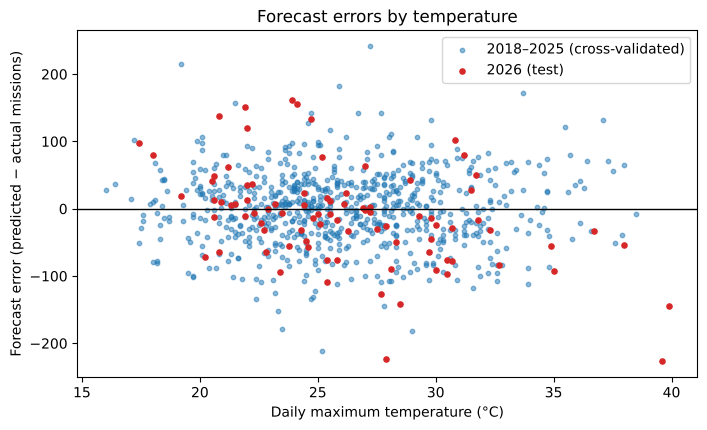

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(model_data.loc[dev, "tmax"], model_data.loc[dev, "model_error"], s=10, alpha=0.5, label="2018–2025 (cross-validated)")
ax.scatter(model_data.loc[test, "tmax"], model_data.loc[test, "model_error"], s=14, color="tab:red", label="2026 (test)")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("Daily maximum temperature (°C)")
ax.set_ylabel("Forecast error (predicted − actual missions)")
ax.set_title("Forecast errors by temperature")
ax.legend()

plt.savefig(figures_folder / "ml_errors_by_temperature.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. How much does the result depend on knowing the temperature?
So far the model was given the measured temperature of the day. A real forecast would have to use a weather forecast, which is never exact. Two checks on the 2026 test:

- **Simulated forecast error:** random errors with a typical size (standard deviation) of 1, 2 and 3°C are added to the 2026 temperatures, 1,000 times each. This is a simplified assumption: real forecast errors are not random from day to day and can be larger in extreme weather.
- **No information about the day's temperature:** the same model without `tmax`. This is the worst case.

In [15]:
rng = np.random.default_rng(42)
perfect_mae = mean_absolute_error(y_test, test_predictions["Linear regression"])

sensitivity = {"Naive (last 7 days)": mean_absolute_error(y_test, naive_test),
               "Model, measured temperature": perfect_mae}

for error_size in [1, 2, 3]:
    simulated = []
    for _ in range(1000):
        X_noisy = X_test.copy()
        X_noisy["tmax"] = X_noisy["tmax"] + rng.normal(0, error_size, len(X_noisy))
        simulated.append(mean_absolute_error(y_test, models["Linear regression"].predict(X_noisy)))
    sensitivity[f"Model, temperature off by about {error_size}°C"] = np.mean(simulated)

columns_without_tmax = [column for column in X.columns if column != "tmax"]
model_without_tmax = LinearRegression().fit(X_dev[columns_without_tmax], y_dev)
sensitivity["Model, no temperature for the day"] = mean_absolute_error(y_test, model_without_tmax.predict(X_test[columns_without_tmax]))

sensitivity_table = pd.DataFrame({"MAE 2026": sensitivity})
sensitivity_table["vs naive (%)"] = (sensitivity_table["MAE 2026"] / sensitivity["Naive (last 7 days)"] - 1) * 100
sensitivity_table.round(1)

,MAE 2026,vs naive (%)
Naive (last 7 days),82.0,0.0
"Model, measured temperature",54.8,-33.2
"Model, temperature off by about 1°C",55.6,-32.2
"Model, temperature off by about 2°C",58.0,-29.3
"Model, temperature off by about 3°C",61.1,-25.5
"Model, no temperature for the day",74.8,-8.8


## 7. What the model learned
A linear regression can be read directly: each coefficient is the change in predicted missions when that feature goes up by one unit and the others stay the same. Weekday and month effects are relative to a Friday in June.

In [16]:
linear_model = models["Linear regression"]   # trained on 2018–2025 in section 5

print(f"Intercept: {linear_model.intercept_:.1f}")
pd.Series(linear_model.coef_, index=X.columns).round(2)

Intercept: 87.6


recent_missions       0.93
tmax                 10.18
recent_tmax          -9.55
weekday_Monday        6.37
weekday_Saturday      4.79
weekday_Sunday      -65.55
weekday_Thursday     -0.49
weekday_Tuesday     -15.18
weekday_Wednesday   -11.39
month_7             -12.25
month_8               2.11
dtype: float64

### A planning example
What does the model forecast for a July Saturday, if the last 7 days averaged 1,400 missions and 26°C?

In [17]:
def forecast(recent_missions, tmax, recent_tmax, weekday, month):
    row = pd.DataFrame(0.0, index=[0], columns=X.columns)
    row["recent_missions"] = recent_missions
    row["tmax"] = tmax
    row["recent_tmax"] = recent_tmax
    for column in [f"weekday_{weekday}", f"month_{month}"]:
        if column in row.columns:      # Friday and June are the reference categories (no column)
            row[column] = 1.0
    return linear_model.predict(row)[0]

for temperature in [22, 26, 30, 34, 38]:
    predicted = forecast(recent_missions=1400, tmax=temperature, recent_tmax=26, weekday="Saturday", month=7)
    print(f"Forecast maximum {temperature}°C  →  {predicted:,.0f} EMS missions")

Forecast maximum 22°C  →  1,357 EMS missions
Forecast maximum 26°C  →  1,398 EMS missions
Forecast maximum 30°C  →  1,439 EMS missions
Forecast maximum 34°C  →  1,479 EMS missions
Forecast maximum 38°C  →  1,520 EMS missions


## 8. Export for Tableau
One row per day with the actual value, the naive forecast and the model forecast. All forecasts are out-of-sample.

In [18]:
tableau_predictions = model_data[["date", "year", "tmax", "hot_day", "evaluation", "ems_missions"]].copy()
tableau_predictions["ems_missions"] = tableau_predictions["ems_missions"].astype(int)
tableau_predictions["naive_forecast"] = model_data["naive"].round(0).astype(int)
tableau_predictions["model_forecast"] = model_data["predicted"].round(0).astype(int)
tableau_predictions["naive_error"] = tableau_predictions["naive_forecast"] - tableau_predictions["ems_missions"]
tableau_predictions["model_error"] = tableau_predictions["model_forecast"] - tableau_predictions["ems_missions"]
tableau_predictions = tableau_predictions.reset_index(drop=True)

assert len(tableau_predictions) == 822 and tableau_predictions["date"].is_unique
assert tableau_predictions.notna().all().all()

tableau_predictions.to_csv(tableau_folder / "tableau_predictions.csv", index=False)
print(tableau_predictions.shape)
tableau_predictions.head()

(822, 10)


,date,year,tmax,hot_day,evaluation,ems_missions,naive_forecast,model_forecast,naive_error,model_error
0,2018-06-01,2018,32.2,1,Cross-validation (2018–2025),1357,1217,1261,-140,-96
1,2018-06-02,2018,26.4,0,Cross-validation (2018–2025),1188,1244,1227,56,39
2,2018-06-03,2018,24.1,0,Cross-validation (2018–2025),1194,1248,1137,54,-57
3,2018-06-04,2018,25.4,0,Cross-validation (2018–2025),1275,1255,1231,-20,-44
4,2018-06-05,2018,23.5,0,Cross-validation (2018–2025),1171,1264,1214,93,43


Two more small tables for the dashboard:
- `tableau_forecast_2026.csv`: the 2026 test summer in long format (one row per day and series), for a line chart of actual vs. forecast.
- `tableau_model_scores.csv`: one row per model and evaluation, for the model comparison.

In [19]:
# Long format: actual, naive forecast and model forecast as three series
series_names = {"ems_missions": "Actual", "naive_forecast": "Naive forecast", "model_forecast": "Model forecast"}

tableau_forecast_2026 = tableau_predictions[tableau_predictions["year"] == 2026].rename(columns=series_names)
tableau_forecast_2026 = tableau_forecast_2026.melt(
    id_vars=["date", "tmax", "hot_day"],
    value_vars=list(series_names.values()),
    var_name="series",
    value_name="missions"
)

assert len(tableau_forecast_2026) == 3 * test.sum()

tableau_forecast_2026.to_csv(tableau_folder / "tableau_forecast_2026.csv", index=False)
print(tableau_forecast_2026.shape)
tableau_forecast_2026.groupby("series")["missions"].agg(["count", "mean"]).round(1)

(261, 5)


,count,mean
series,,
Actual,87,1429.7
Model forecast,87,1417.8
Naive forecast,87,1430.3


In [20]:
# Model scores from sections 3 and 5, with ready-made text labels for Tableau
tableau_model_scores = pd.concat([
    cv_table.assign(evaluation="Cross-validation (2018–2025)"),
    test_table.assign(evaluation="Test (2026)"),
]).reset_index(names="model")

tableau_model_scores = tableau_model_scores.rename(columns={
    "MAE": "mae", "RMSE": "rmse", "R2": "r2", "MAE vs naive (%)": "mae_vs_naive_pct"
})
tableau_model_scores = tableau_model_scores[["model", "evaluation", "mae", "rmse", "r2", "mae_vs_naive_pct"]].round(2)

tableau_model_scores["mae_label"] = tableau_model_scores["mae"].map("{:.1f}".format)
tableau_model_scores["change_label"] = tableau_model_scores["mae_vs_naive_pct"].map(lambda pct: f"−{abs(pct):.0f}%")
tableau_model_scores.loc[tableau_model_scores["model"] == "Naive (last 7 days)", "change_label"] = "baseline"

assert len(tableau_model_scores) == 8 and tableau_model_scores.notna().all().all()

tableau_model_scores.to_csv(tableau_folder / "tableau_model_scores.csv", index=False)
tableau_model_scores

,model,evaluation,mae,rmse,r2,mae_vs_naive_pct,mae_label,change_label
0,Naive (last 7 days),Cross-validation (2018–2025),56.90,72.66,0.55,0.00,56.9,baseline
1,Linear regression,Cross-validation (2018–2025),42.81,55.15,0.74,-24.76,42.8,−25%
2,Random forest,Cross-validation (2018–2025),47.42,61.05,0.68,-16.65,47.4,−17%
3,Gradient boosting,Cross-validation (2018–2025),45.31,58.24,0.71,-20.37,45.3,−20%
4,Naive (last 7 days),Test (2026),82.02,105.04,0.28,0.00,82.0,baseline
5,Linear regression,Test (2026),54.81,73.94,0.64,-33.18,54.8,−33%
6,Random forest,Test (2026),76.83,111.16,0.19,-6.32,76.8,−6%
7,Gradient boosting,Test (2026),78.28,115.34,0.13,-4.56,78.3,−5%


## Main findings

**In a retrospective experiment, next-day EMS demand can be predicted clearly better than with a naive rule, and temperature accounts for most of the gain.**

1. **The model beats the naive forecast.** Linear regression has a cross-validated error of 42.8 missions per day, against 56.9 for the naive forecast (−25%). That is about 3–4% of daily demand. It was better than the naive forecast in all eight summers from 2018 to 2025.
2. **Temperature carries predictive information.** A model that only knows recent demand and the calendar has an error of 53.4 missions. Adding the day's and recent temperature brings it down to 42.8 (−20%).
3. **The result holds on an unseen summer.** For 2026 the error is 54.8 missions against 82.0 for the naive forecast (−33%, R² = 0.64).
4. **It depends on knowing the temperature, but not on knowing it exactly.** With a simulated temperature error of about 2°C the 2026 error rises to about 58 missions. Without any information about the day's temperature it is 74.8, still below the naive 82.0.
5. **The simplest model wins.** Random forest and gradient boosting are slightly worse in cross-validation (47.4 and 45.3) and fail in 2026 (76.8 and 78.3). Tree models cannot predict values outside the range they were trained on, and demand grows every year (2026 average: 1,430 missions per day, 2018–2025: 1,266).
6. **What the model learned.** Each °C above the average of the previous week adds about 10 missions to the prediction (`tmax` +10.2, `recent_tmax` −9.6). This matches Notebook 04 (+0.84 index points per °C, about 11 missions at the average level). Sundays have about 66 fewer missions than Fridays.
7. **Extreme heat is underestimated.** On the 19 hot days of 2026 the model was on average 46 missions too low. At the peak of the record heatwave (28 June, 39.6°C) it predicted 1,613 missions against 1,840 actual. Temperatures of almost 40°C lie outside the training data (maximum 38.5°C). In 2018–2025 there was no systematic bias on hot days (−1.8).

**Limitations**
- This is a retrospective experiment. The model was never tested with real weather forecasts, and the simulated temperature errors are a simplification.
- Cross-validation is not chronological; only the 2026 test is.
- It assumes yesterday's mission count is available when the prediction is made.
- The final test is a single summer (87 days).
- Summer months only, one weather station, no public holidays or large events.
- A linear model assumes the same effect per °C at every temperature; finding 7 shows this breaks down in extreme heat.
- A prediction, not a causal estimate.